# JS10 Tugas Lab: Klasifikasi MNIST dengan ANN

Tugas jobsheet 10: klasifikasi digit tulisan tangan MNIST memakai ANN dari TensorFlow. Yang dieksplorasi di sini adalah pra pengolahan dan arsitektur; CNN sengaja tidak dipakai karena itu materi JS11.

MNIST berisi 60.000 citra latih dan 10.000 citra uji berukuran 28x28 piksel, dengan 10 kelas digit.

## 1. Import Library dan Load Dataset

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

tf.keras.utils.set_random_seed(0)

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()
print(X_train.shape, X_test.shape, X_train.dtype)

(60000, 28, 28) (10000, 28, 28) uint8


## 2. Pra Pengolahan

Dua hal yang dilakukan: skala piksel diubah dari 0-255 ke 0-1, dan citra 28x28 diratakan menjadi vektor 784 angka karena `Dense` hanya menerima input satu dimensi. Label dibiarkan sebagai angka 0-9 dan dipakai bersama loss `sparse_categorical_crossentropy`.

In [2]:
X_train = X_train.astype('float32') / 255.0
X_test  = X_test.astype('float32') / 255.0

X_train_flat = X_train.reshape(len(X_train), -1)
X_test_flat  = X_test.reshape(len(X_test), -1)

print(X_train_flat.shape, X_test_flat.shape, X_train_flat.min(), X_train_flat.max())

(60000, 784) (10000, 784) 0.0 1.0


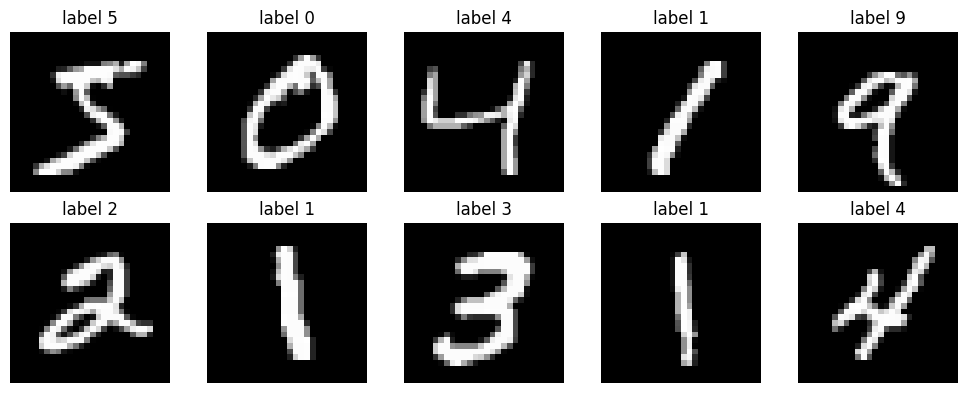

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, img, label in zip(axes.ravel(), X_train, y_train):
    ax.imshow(img, cmap='gray')
    ax.set_title(f'label {label}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. Bangun Model ANN

Arsitektur: 784 input, hidden 256 dan 128 dengan ReLU, lalu 10 output softmax. `Dropout` dipasang setelah tiap hidden layer untuk menahan overfitting, karena 60.000 sampel dengan 200 ribu parameter cukup mudah dihafal.

In [4]:
model = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(10, activation='softmax'),
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Latih Model

In [5]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
)

history = model.fit(
    X_train_flat, y_train,
    epochs=20,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=0,
)

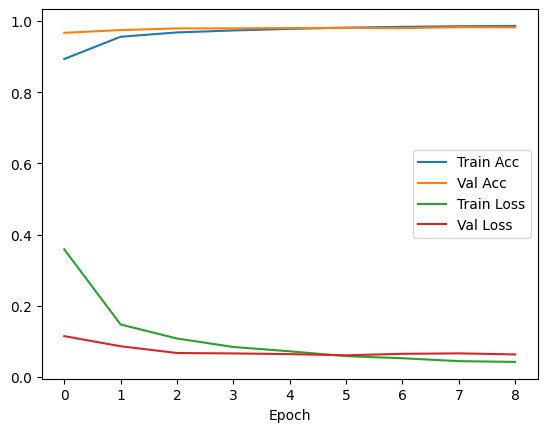

In [6]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

Akurasi latih dan validasi bergerak bersama, sedangkan loss validasi berhenti turun lebih dulu. Di titik itu `EarlyStopping` mengembalikan bobot terbaik, jadi pelatihan berhenti sebelum model mulai menghafal.

## 5. Evaluasi pada Data Uji

In [7]:
test_loss, test_acc = model.evaluate(X_test_flat, y_test, verbose=0)
print('Akurasi test:', test_acc)

Akurasi test: 0.9793000221252441


In [8]:
y_pred = np.argmax(model.predict(X_test_flat, verbose=0), axis=1)

print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
cm

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.98      0.98      1032
           3       0.97      0.98      0.97      1010
           4       0.98      0.98      0.98       982
           5       0.98      0.97      0.98       892
           6       0.98      0.99      0.98       958
           7       0.97      0.98      0.98      1028
           8       0.97      0.97      0.97       974
           9       0.99      0.97      0.98      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



array([[ 971,    1,    0,    2,    0,    1,    3,    1,    1,    0],
       [   0, 1123,    3,    0,    0,    0,    2,    2,    5,    0],
       [   3,    0, 1010,    4,    1,    1,    2,    5,    5,    1],
       [   2,    0,    4,  990,    0,    4,    0,    5,    3,    2],
       [   0,    0,    4,    0,  967,    0,    3,    2,    3,    3],
       [   2,    0,    0,   12,    1,  864,    7,    1,    5,    0],
       [   3,    3,    0,    1,    2,    3,  944,    0,    2,    0],
       [   0,    4,   11,    3,    0,    0,    0, 1004,    3,    3],
       [   4,    1,    1,    9,    5,    5,    1,    3,  941,    4],
       [   4,    3,    0,    4,    9,    1,    0,    7,    2,  979]])

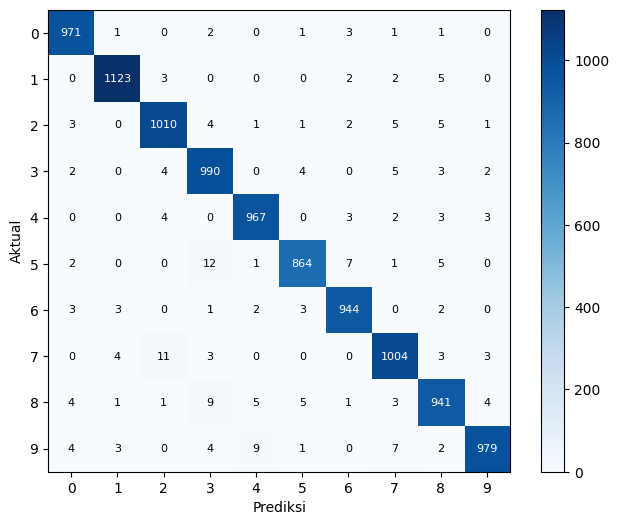

In [9]:
plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xticks(range(10), range(10))
plt.yticks(range(10), range(10))
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=8)
plt.show()

## 6. Lihat Kesalahan Prediksi

Jumlah salah: 207 dari 10000


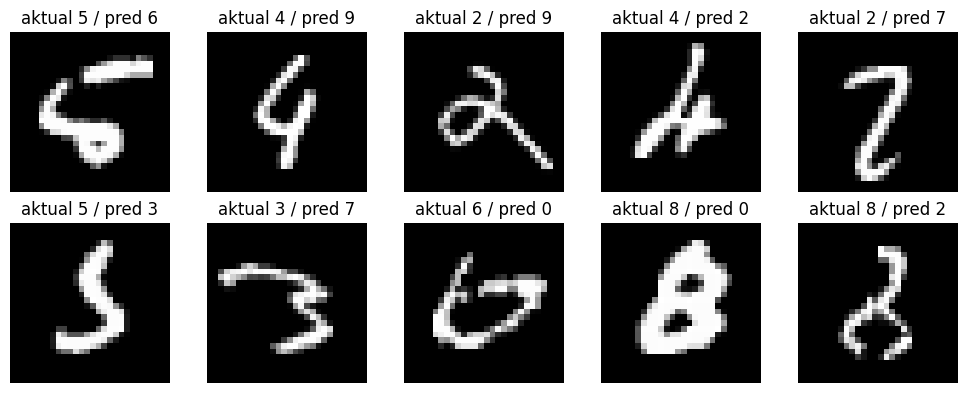

In [10]:
wrong = np.where(y_pred != y_test)[0]
print('Jumlah salah:', len(wrong), 'dari', len(y_test))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, idx in zip(axes.ravel(), wrong[:10]):
    ax.imshow(X_test[idx], cmap='gray')
    ax.set_title(f'aktual {y_test[idx]} / pred {y_pred[idx]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

Kesalahan yang tersisa umumnya pada digit yang memang ambigu secara bentuk, misalnya 4 yang mirip 9 atau 3 yang mirip 8. ANN `Dense` membaca piksel sebagai daftar angka lepas, jadi posisi dan bentuk lokal tidak dipakai secara eksplisit. Di situ CNN pada JS11 punya keunggulan.

## 7. Simpan Model

In [11]:
model.save('mnist_ann_model.keras')